In [1]:
# Newton–Raphson Method using Python

from __future__ import annotations

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import digamma, polygamma, gammaln

# ----------------------------------------------------------
# 1. GAMMA(shape=alpha, rate=1) likelihood
# ----------------------------------------------------------
def gamma_ll(a: float, data: np.ndarray) -> float:
    if a <= 0:
        return -np.inf
    n = len(data)
    return (a - 1.0) * np.log(data).sum() - data.sum() - n * gammaln(a)


def gamma_score(a: float, data: np.ndarray) -> float:
    return float(np.log(data).sum() - len(data) * digamma(a))


def gamma_hessian(a: float, data: np.ndarray) -> float:
    return float(-len(data) * polygamma(1, a))


def gamma_newton(data: np.ndarray, a0: float = 2.0,
                 tol: float = 1e-9, max_iter: int = 60,
                 safeguard: bool = True) -> tuple[np.ndarray, str]:
    """Newton iteration with optional step-halving to keep a>0 and improve ll."""
    if a0 <= 0:
        raise ValueError("Initial shape must be positive")
    path = [float(a0)]
    for _ in range(max_iter):
        a = path[-1]
        score, hess = gamma_score(a, data), gamma_hessian(a, data)
        step = -score / hess
        scale = 1.0
        new_a = a + step
        if safeguard:
            for _ in range(60):
                if new_a > 0 and np.isfinite(new_a) and gamma_ll(new_a, data) >= gamma_ll(a, data) - 1e-10:
                    break
                scale *= 0.5
                new_a = a + scale * step
            else:
                return np.asarray(path), "line search failed"
        elif new_a <= 0 or not np.isfinite(new_a):
            return np.asarray(path), "left the positive parameter domain"
        path.append(float(new_a))
        if abs(new_a - a) <= tol * (1 + abs(a)):
            return np.asarray(path), "step tolerance reached"
    return np.asarray(path), "maximum iterations reached"


def plot_gamma_samples() -> None:
    rng = np.random.default_rng(100)
    true_alpha = 5.0
    # Same demonstration as the R notes, with NumPy's RNG.
    datasets = {10: rng.gamma(shape=true_alpha, scale=1.0, size=10),
                1000: rng.gamma(shape=true_alpha, scale=1.0, size=1000)}
    for n, data in datasets.items():
        path, status = gamma_newton(data, a0=2.0, safeguard=True)
        grid = np.linspace(0.3, 10.0, 400)  # start above zero: Gamma shape > 0
        ll_per_obs = np.array([gamma_ll(a, data) / n for a in grid])
        plt.figure(figsize=(7.6, 4.7))
        plt.plot(grid, ll_per_obs, label="Log-likelihood / n")
        plt.axvline(true_alpha, color="red", ls="--", label="Generating shape")
        plt.axvline(path[-1], color="blue", ls="--", label="Computed MLE")
        plt.plot(path, [gamma_ll(a, data) / n for a in path],
                 "o-", ms=4, label="Newton iterates")
        plt.xlabel(r"Shape $\alpha$")
        plt.ylabel(r"$\ell(\alpha)/n$")
        plt.title(f"Gamma likelihood: n={n}")
        plt.legend()
        plt.tight_layout()
        plt.show()
        print(f"Gamma n={n}: shape truth={true_alpha:.3f}, "
              f"MLE={path[-1]:.6f}, iterations={len(path)-1}, {status}")




In [2]:
# ----------------------------------------------------------
# 2. CAUCHY(location=mu, scale=1) likelihood
# ----------------------------------------------------------
def cauchy_ll(mu: float, data: np.ndarray) -> float:
    r = data - mu
    return float(-len(data) * np.log(np.pi) - np.log1p(r * r).sum())


def cauchy_score(mu: float, data: np.ndarray) -> float:
    r = data - mu
    return float((2.0 * r / (1.0 + r * r)).sum())


def cauchy_hessian(mu: float, data: np.ndarray) -> float:
    r = data - mu
    return float((2.0 * (r * r - 1.0) / (1.0 + r * r) ** 2).sum())


def cauchy_newton(data: np.ndarray, mu0: float,
                  tol: float = 1e-8, max_iter: int = 40) -> tuple[np.ndarray, str]:
    """Raw Newton steps: deliberately show bad starts and nonconcavity."""
    path = [float(mu0)]
    for _ in range(max_iter):
        mu = path[-1]
        score, hess = cauchy_score(mu, data), cauchy_hessian(mu, data)
        if abs(hess) < 1e-9:
            return np.asarray(path), "near-zero curvature (unsafe step)"
        next_mu = mu - score / hess
        if not np.isfinite(next_mu) or abs(next_mu) > 1e7:
            return np.asarray(path), "divergence / numerical overflow"
        path.append(float(next_mu))
        if abs(next_mu - mu) < tol:
            kind = "local maximum" if cauchy_hessian(next_mu, data) < 0 else "not a local maximum"
            return np.asarray(path), f"step tolerance reached; {kind}"
    return np.asarray(path), "maximum iterations reached"


def plot_cauchy_examples() -> None:
    for seed in [1, 10, 33]:
        rng = np.random.default_rng(seed)
        data = 5 + rng.standard_cauchy(size=4)
        grid = np.linspace(-10, 40, 1000)
        vals = np.array([cauchy_ll(mu, data) for mu in grid])
        plt.figure(figsize=(8, 4.8))
        plt.plot(grid, vals, color="black", label="Cauchy log-likelihood")
        for mu0, color, label in [(float(np.median(data)), "blue", "sample median"),
                                  (7.0, "red", "start = 7"),
                                  (19.0, "green", "start = 19")]:
            path, status = cauchy_newton(data, mu0)
            valid = path[(path >= grid[0]) & (path <= grid[-1])]
            plt.plot(valid, [cauchy_ll(mu, data) for mu in valid],
                     "o-", color=color, label=f"{label}: {status}", alpha=.85)
        plt.axvline(5, color="gray", ls="--", label="Generating location")
        plt.xlabel(r"Location $\mu$")
        plt.ylabel("Log-likelihood")
        plt.title(f"Cauchy likelihood, n=4, NumPy seed={seed}")
        plt.legend(fontsize=8)
        plt.tight_layout()
        plt.show()
        print(f"Cauchy seed={seed}, data={np.round(data, 3)}")

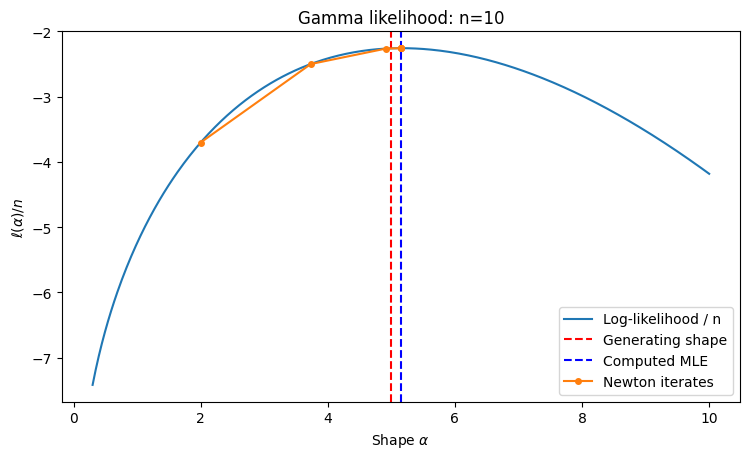

Gamma n=10: shape truth=5.000, MLE=5.157113, iterations=6, step tolerance reached


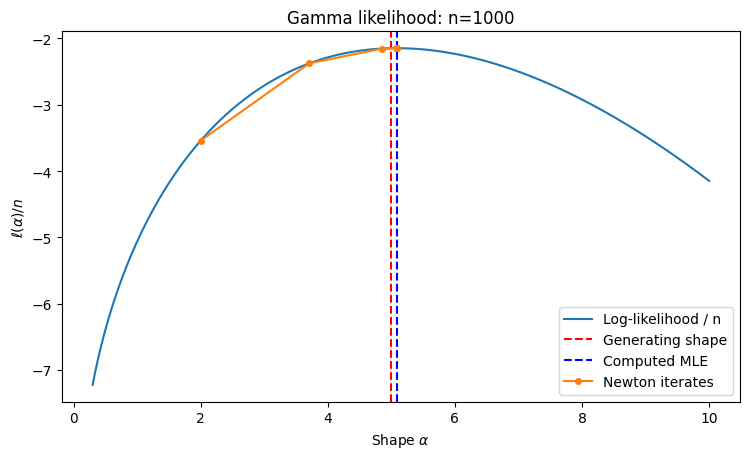

Gamma n=1000: shape truth=5.000, MLE=5.082342, iterations=6, step tolerance reached


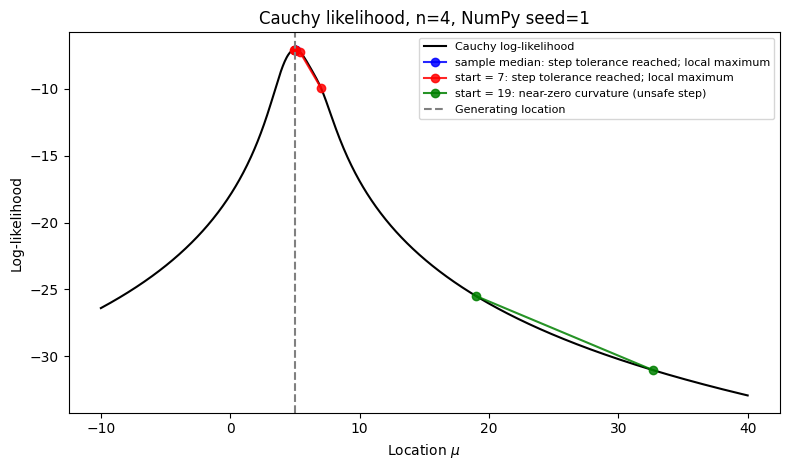

Cauchy seed=1, data=[5.421 4.746 7.028 4.076]


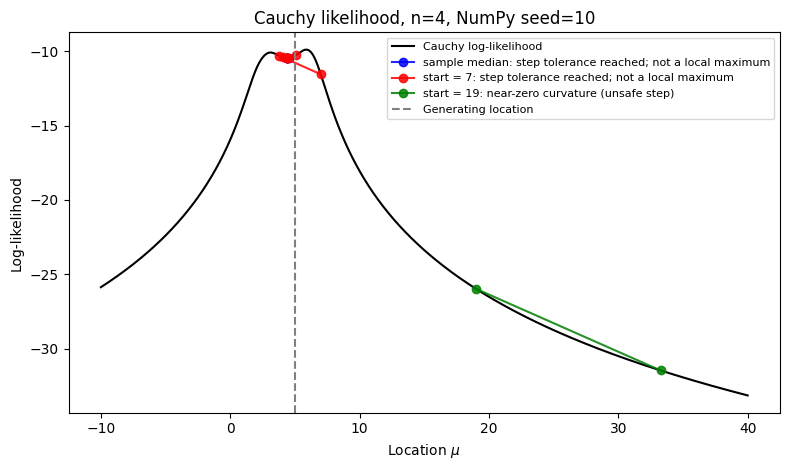

Cauchy seed=10, data=[6.522 2.072 3.035 5.983]


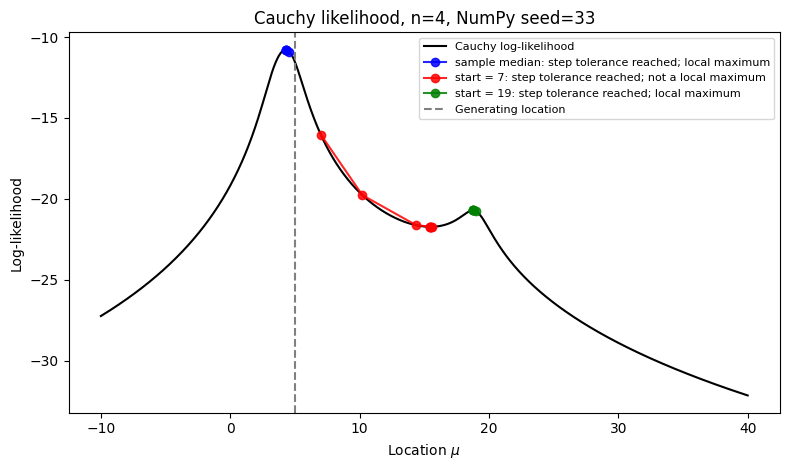

Cauchy seed=33, data=[ 4.292 18.981  3.432  4.842]
Ridge beta after 1 Newton step: [0.63959391 0.91370558]
Ridge analytic minimizer:       [0.63959391 0.91370558]
Difference (numerical rounding): 3.510833468576701e-16


In [3]:
# ----------------------------------------------------------
# 3. RIDGE REGRESSION: one exact Newton step
# ----------------------------------------------------------
def ridge_newton_example() -> None:
    X = np.array([[1.0, 0.0], [1.0, 1.0],
                  [1.0, 2.0], [1.0, 3.0]])
    y = np.array([1.0, 2.0, 2.0, 4.0])
    lam = 1.5  # includes penalty on both coefficients in this demonstration
    start = np.array([-1.0, 4.0])
    H = X.T @ X + lam * np.eye(X.shape[1])
    grad = H @ start - X.T @ y
    beta1 = start - np.linalg.solve(H, grad)  # use solve, not an explicit inverse
    beta_star = np.linalg.solve(H, X.T @ y)
    print("Ridge beta after 1 Newton step:", beta1)
    print("Ridge analytic minimizer:      ", beta_star)
    print("Difference (numerical rounding):", np.linalg.norm(beta1 - beta_star))
    assert np.allclose(beta1, beta_star)


if __name__ == "__main__":
    plot_gamma_samples()
    plot_cauchy_examples()
    ridge_newton_example()
